# 📈 Stock Market Analysis Project
This project analyzes historical stock market data (`AAPL.csv`) to identify trends and patterns in stock prices over time[cite: 1]. In this notebook, we will visualize stock performance, moving averages, trading volume, and volatility step-by-step[cite: 1].


In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Set visual style
sns.set_theme(style="darkgrid")
plt.rcParams["figure.figsize"] = (14, 7)

# Load the CSV file
df = pd.read_csv("AAPL.csv")

# Convert the Date column to datetime and set it as the index
df["Date"] = pd.to_datetime(df["Date"])
df.set_index("Date", inplace=True)

print("CSV file successfully loaded!")
print(df.head())


CSV file successfully loaded!
                Open      High       Low     Close  Adj Close     Volume
Date                                                                    
1980-12-12  0.128348  0.128906  0.128348  0.128348   0.099319  469033600
1980-12-15  0.122210  0.122210  0.121652  0.121652   0.094137  175884800
1980-12-16  0.113281  0.113281  0.112723  0.112723   0.087228  105728000
1980-12-17  0.115513  0.116071  0.115513  0.115513   0.089387   86441600
1980-12-18  0.118862  0.119420  0.118862  0.118862   0.091978   73449600


## 🛠️ Step 2: Data Filtering and Technical Indicators Calculation
Instead of using very old data, we will filter the dataset for recent data (from `2020` onwards) and calculate key indicators[cite: 1]:
* **50-day Simple Moving Average (SMA_50)**: Used to identify short-term trends.
* **200-day Simple Moving Average (SMA_200)**: Used to identify long-term trends.
* **Daily Returns Percentage**: Used to measure risk and volatility.

In [ ]:
# Filter data from 2020 onwards
df_recent = df.loc["2020-01-01":].copy()

# Calculate Moving Averages
df_recent["SMA_50"] = df_recent["Close"].rolling(window=50).mean()
df_recent["SMA_200"] = df_recent["Close"].rolling(window=200).mean()

# Calculate Daily Returns Percentage
df_recent["Daily_Return"] = df_recent["Close"].pct_change() * 100

# View summary statistics
df_recent[["Close", "Volume", "Daily_Return"]].describe().round(2)

,Close,Volume,Daily_Return
count,989.00,9.890000e+02,988.00
mean,139.88,9.973558e+07,0.12
std,32.83,5.445656e+07,2.13
min,56.09,2.404830e+07,-12.86
25%,123.00,6.472720e+07,-0.92
50%,145.49,8.543840e+07,0.11
75%,165.30,1.161204e+08,1.30
max,196.45,4.265100e+08,11.98


In [ ]:
# 50-day aur 200-day Simple Moving Average (SMA)
df['SMA_50'] = df['Close'].rolling(window=50).mean()
df['SMA_200'] = df['Close'].rolling(window=200).mean()

# Daily Returns Percentage
df['Daily_Return'] = df['Close'].pct_change() * 100

# Summary  of statistics 
df[['Close', 'Volume', 'Daily_Return']].describe().round(2)

,Close,Volume,Daily_Return
count,10836.00,1.083600e+04,10835.00
mean,19.80,3.219041e+08,0.11
std,41.44,3.364615e+08,2.80
min,0.05,0.000000e+00,-51.87
25%,0.29,1.164436e+08,-1.28
50%,0.51,2.094288e+08,0.00
75%,18.80,4.017468e+08,1.45
max,196.45,7.421641e+09,33.23


## 📊 Step 3: Stock Price vs Moving Averages Analysis
Here, we visualize Apple's closing price alongside the 50-day and 200-day Moving Averages using a line plot to easily interpret overall market trends[cite: 1].

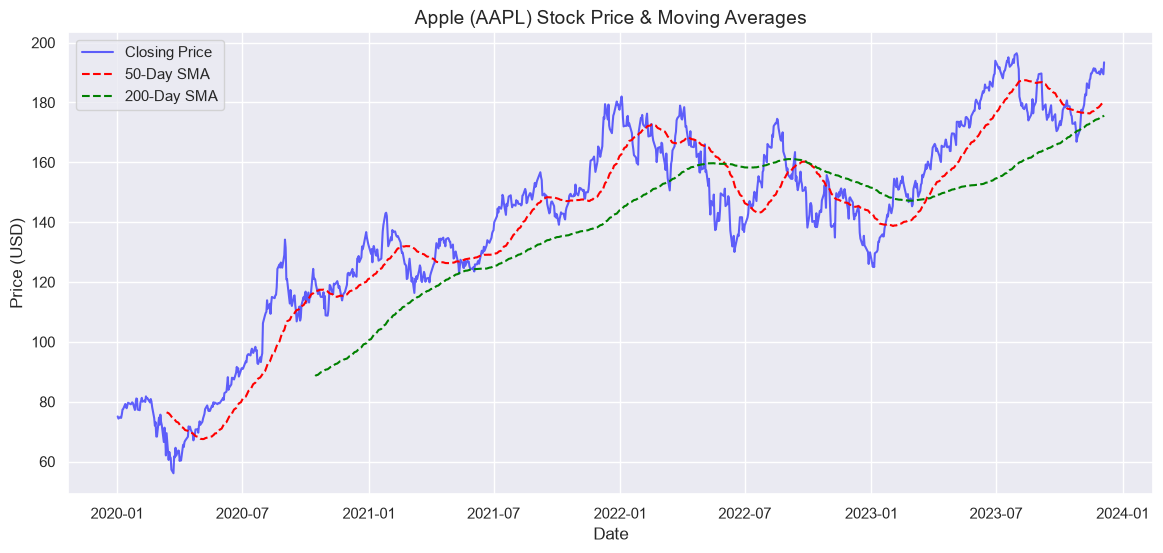

In [ ]:
plt.figure(figsize=(14, 6))
plt.plot(
    df_recent.index,
    df_recent["Close"],
    label="Closing Price",
    alpha=0.6,
    color="blue",
)
plt.plot(
    df_recent.index,
    df_recent["SMA_50"],
    label="50-Day SMA",
    color="red",
    linestyle="--",
)
plt.plot(
    df_recent.index,
    df_recent["SMA_200"],
    label="200-Day SMA",
    color="green",
    linestyle="--",
)

plt.title("Apple (AAPL) Stock Price & Moving Averages", fontsize=14)
plt.xlabel("Date", fontsize=12)
plt.ylabel("Price (USD)", fontsize=12)
plt.legend(loc="upper left")
plt.show()

## 📉 Step 4: Trading Volume Analysis
Trading volume shows how many shares were traded on a given day[cite: 1]. This helps gauge market liquidity and investor activity levels.

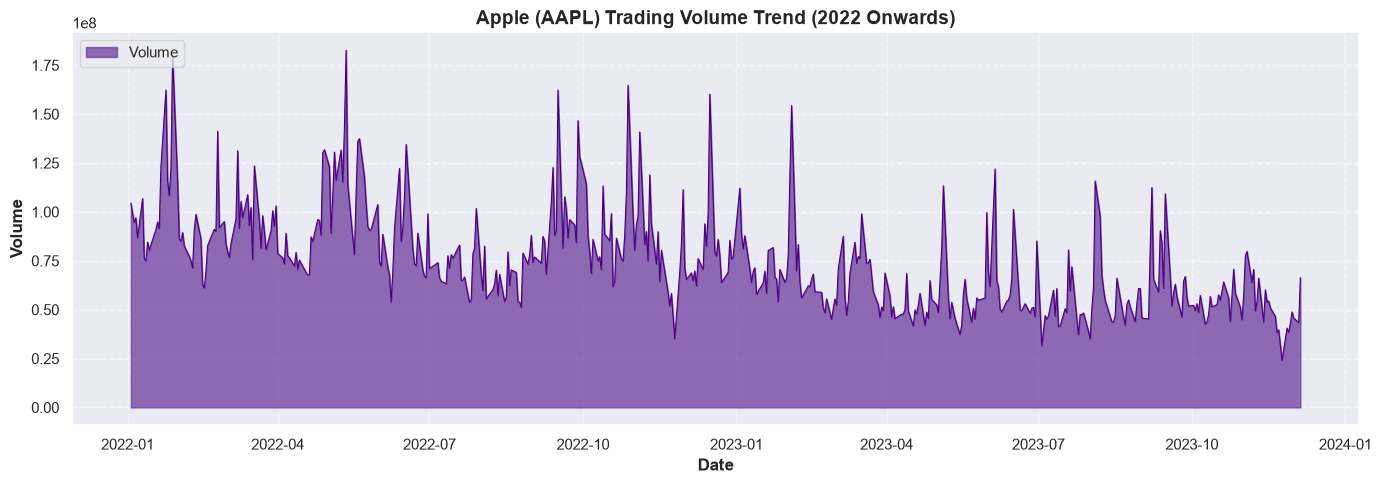

In [ ]:
plt.figure(figsize=(14, 5))
# Filter the last 2 years of data so that the bars/area look clear and bold
df_vol = df.loc["2022-01-01":].copy()

# Area plot (Filled curve) looks the cleanest and most professional for trading volume
plt.fill_between(
    df_vol.index,
    df_vol["Volume"],
    color="rebeccapurple",
    alpha=0.7,
    label="Volume",
)
plt.plot(df_vol.index, df_vol["Volume"], color="indigo", linewidth=0.8)

plt.title(
    "Apple (AAPL) Trading Volume Trend (2022 Onwards)",
    fontsize=14,
    fontweight="bold",
)
plt.xlabel("Date", fontsize=12, fontweight="bold")
plt.ylabel("Volume", fontsize=12, fontweight="bold")
plt.legend(loc="upper left")
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

## 📐 Step 5: Daily Returns Distribution & Risk Analysis
To analyze stock volatility and daily price fluctuations, we plot a histogram along with a KDE curve for daily returns[cite: 1].

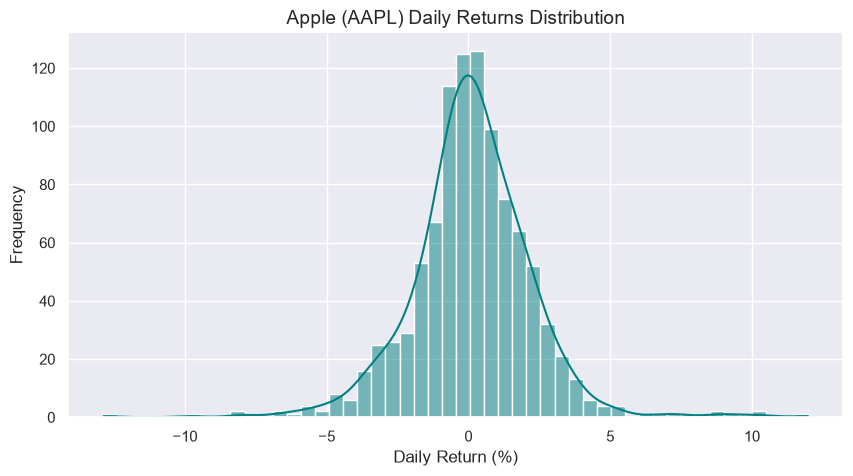

In [ ]:
plt.figure(figsize=(10, 5))
sns.histplot(df_recent["Daily_Return"].dropna(), kde=True, color="teal", bins=50)
plt.title("Apple (AAPL) Daily Returns Distribution", fontsize=14)
plt.xlabel("Daily Return (%)", fontsize=12)
plt.ylabel("Frequency", fontsize=12)
plt.show()